# Linear Classification Model:
Architecture: Linear -> Softmax.<br> 
Hàm Loss: Cross Entropy.<br>   
Dataset: CIFAR-10 (5 Data Batch gồm 10000 ảnh mỗi 32 x 32 mỗi Batch).<br>
Train: 49000 ảnh.<br> 
Validation: 1000 ảnh.<br> 
Gradient Descent: SGD.<br> 

In [14]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

Mở file Data_Batch. Vì nó định dạng Pickle nên phải dùng hàm này (được web cho sẵn).

In [15]:
def unpickle(file):
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

Mở Data_batch_1, hàm trả về dict với key và value có thể in ra để xem. 
y được lấy value là list nên phải chuyển qua numpy array còn X là numpy array sẵn.

In [16]:
file = "/Users/thinh1307/Documents/VSCODE/CS231n/CIFAR-10/cifar-10-batches-py/data_batch_1"
file1 = unpickle(file)
X = file1[b'data']
y = np.array(file1[b'labels'])

Giàn ảnh lại 3 x 32 x 32 vì (32 x 32 số đầu là Red xong đến Green xong đến Blue). Sau đó sắp xếp lại vì matplotlib bắt định dạng m x n x 3.<br>
Hàm reshape(kích thước mới của ma trận).<br>
Hàm transpose(chiều cũ theo thứ tự tương đương).

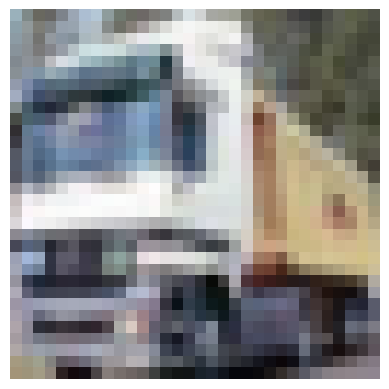

In [17]:
image = X[1].reshape(3, 32, 32).transpose(1,2,0)
plt.imshow(image)
plt.axis("off")
plt.show()

Lấy tất cả 5 file data ra và bỏ vô list để bắt đầu Model.<br>
Khởi tạo list x = [].<br>
hàm append() để thêm vào list. 

In [18]:
X_train =[]
y_train =[]
for i in range(1, 6):
    file = f"/Users/thinh1307/Documents/VSCODE/CS231n/CIFAR-10/cifar-10-batches-py/data_batch_{i}"
    X_train.append(unpickle(file)[b'data'])
    y_train.append(np.array(unpickle(file)[b'labels']))

X_train, y_train

([array([[ 59,  43,  50, ..., 140,  84,  72],
         [154, 126, 105, ..., 139, 142, 144],
         [255, 253, 253, ...,  83,  83,  84],
         ...,
         [ 71,  60,  74, ...,  68,  69,  68],
         [250, 254, 211, ..., 215, 255, 254],
         [ 62,  61,  60, ..., 130, 130, 131]],
        shape=(10000, 3072), dtype=uint8),
  array([[ 35,  27,  25, ..., 169, 168, 168],
         [ 20,  20,  18, ..., 111,  97,  51],
         [116, 115, 155, ...,  18,  84, 124],
         ...,
         [127, 139, 155, ..., 197, 192, 191],
         [190, 200, 208, ..., 163, 182, 192],
         [177, 174, 182, ..., 119, 127, 136]],
        shape=(10000, 3072), dtype=uint8),
  array([[ 26,  17,  13, ...,  27,  26,  27],
         [ 94, 101,  95, ..., 182, 184, 155],
         [183, 158, 166, ..., 250, 250, 250],
         ...,
         [175, 200, 207, ..., 124,  49,  32],
         [ 28,  59,  67, ...,  36,  44,  41],
         [ 62,  40,  61, ..., 127, 124, 116]],
        shape=(10000, 3072), dtype=uint8)

Vì X_train, y_train là list nên giờ sử dụng hàm concatenate của numpy để ghép cả 5 mảng vào, theo chiều 0, thay vì liệt kê mảng thì chúng là list sẵn nên chỉ cần dùng tên list (đại diện cho 5 mảng). Sau khi nối thì hàm trả về array.<br>
Hàm np.concatenate(các ma trận cần ghép, axis ghép).

In [19]:
X_train = np.concatenate(X_train, axis=0)
y_train = np.concatenate(y_train, axis=0)

X_train.shape, y_train.shape, type(X_train), type(y_train)

((50000, 3072), (50000,), numpy.ndarray, numpy.ndarray)

Trích xuất 1000 test cuối để làm validation

In [20]:
num_validation = 1000

X_val = X_train[:num_validation]
y_val = y_train[:num_validation]

X_train = X_train[num_validation:]
y_train = y_train[num_validation:]

X_val.shape, y_val.shape, X_train.shape, y_train.shape

((1000, 3072), (1000,), (49000, 3072), (49000,))

Chuẩn hóa các vector ảnh từ giá trị [0, 255] về [0, 1]. 

In [21]:
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0

X_train, X_val

(array([[0.9490196 , 0.9490196 , 0.95686275, ..., 0.5372549 , 0.5372549 ,
         0.5294118 ],
        [0.21960784, 0.34117648, 0.50980395, ..., 0.36078432, 0.3647059 ,
         0.3372549 ],
        [0.39215687, 0.38431373, 0.76862746, ..., 0.24313726, 0.24313726,
         0.1882353 ],
        ...,
        [0.13725491, 0.15686275, 0.16470589, ..., 0.3019608 , 0.25882354,
         0.19607843],
        [0.7411765 , 0.7294118 , 0.7254902 , ..., 0.6627451 , 0.67058825,
         0.67058825],
        [0.8980392 , 0.9254902 , 0.91764706, ..., 0.6784314 , 0.63529414,
         0.6313726 ]], shape=(49000, 3072), dtype=float32),
 array([[0.23137255, 0.16862746, 0.19607843, ..., 0.54901963, 0.32941177,
         0.28235295],
        [0.6039216 , 0.49411765, 0.4117647 , ..., 0.54509807, 0.5568628 ,
         0.5647059 ],
        [1.        , 0.99215686, 0.99215686, ..., 0.3254902 , 0.3254902 ,
         0.32941177],
        ...,
        [0.5686275 , 0.5137255 , 0.4509804 , ..., 0.34901962, 0.34509805

Tạo ngẫu nhiên các ma trận W và b trong lớp tuyến tính scores = X @ W + b.<br>
Hàm np.random.randn(kích thước ma trận random). 

In [22]:
D = 3072
C = 10

W = 0.001 * np.random.randn(D, C)
b = np.zeros(C)

In [23]:
scores = X_train @ W + b

scores.shape, X_train.shape, W.shape, b.shape

((49000, 10), (49000, 3072), (3072, 10), (10,))

Để tránh tình trạng tràn số, ta lấy kết quả và trừ đi kết quả lớn nhất (không làm ảnh hưởng kết quả softmax).<br>
Hàm max(mảng cần tìm, chiều, trả về đúng chiều hay mất).<br>
Hàm sum(mảng cần tính tổng, chiều, trả về đúng chiều hay mất). 

In [24]:
# Trừ giá trị lớn nhất của mỗi ảnh
scores -= np.max(scores, axis=1, keepdims=True)
# Lấy hàm mũ của các điểm số
exp_scores = np.exp(scores)
# Chuyển điểm số thành xác suất
probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
print(probs.shape)
print(probs[0])
print(np.sum(probs[0]))

(49000, 10)
[0.10600899 0.09950882 0.09829323 0.09515836 0.10401571 0.09230823
 0.09836454 0.10078234 0.0999236  0.10563618]
1.0


Tính Độ mất mát trung bình của kết quả.<br>
Nhớ rằng Hàm Loss (Cross Entropy Loss): loss = -np.log(probs[0, y_train[0]]) (lấy kết quả từ class đúng của mỗi data).<br>
Giải thích index của probs: np.arange(N) sẽ trả về array từ 0 đến N, y_train là mảng chứa class đúng của từng dòng data, kết hợp lại thì sẽ ra loss class đúng của mỗi hàng. 

In [25]:
N = X_train.shape[0]

loss = -np.mean(
    np.log(probs[np.arange(N), y_train])
)

loss

np.float64(2.3026188226166573)

Train model bằng cách lặp việc tính Loss sau đó cập nhật trọng số 1000 lần để hiệu chỉnh. 
"Gradient của scores". 
dscores = probs.copy()
dscores[np.arange(N), y_train] -= 1
dscores /= N

"Gradient của W và b". 
dW = X_train.T @ dscores
db = np.sum(dscores, axis=0)

"Cập nhật parameters". 
learning_rate = 1e-3

W -= learning_rate * dW
b -= learning_rate * db

In [26]:
N = X_train.shape[0]
learning_rate = 1e-3

for i in range(1000):

    # 1. Tính scores
    scores = X_train @ W + b

    # 2. Softmax
    scores -= np.max(scores, axis=1, keepdims=True)

    exp_scores = np.exp(scores)

    probs = exp_scores / np.sum(
        exp_scores,
        axis=1,
        keepdims=True
    )

    # 3. Tính Loss
    loss = -np.mean(
        np.log(probs[np.arange(N), y_train])
    )

    # 4. Tính gradient
    dscores = probs.copy()
    dscores[np.arange(N), y_train] -= 1
    dscores /= N

    dW = X_train.T @ dscores
    db = np.sum(dscores, axis=0)

    # 5. Cập nhật W và b
    W -= learning_rate * dW
    b -= learning_rate * db

    # In loss mỗi 100 vòng
    if i % 100 == 0:
        print(f"iteration {i}: loss = {loss}")

iteration 0: loss = 2.3026188226166573
iteration 100: loss = 2.230132247117013
iteration 200: loss = 2.179366569156421
iteration 300: loss = 2.1409017040206733
iteration 400: loss = 2.11065296569118
iteration 500: loss = 2.0861119801154917
iteration 600: loss = 2.065686119613516
iteration 700: loss = 2.048325695955696
iteration 800: loss = 2.03331413179205
iteration 900: loss = 2.0201467330384797


In ra kết quả sau khi train, và dùng kết quả đó kiểm tra trên tập Validation.<br>
Đúng là 1, sai là 0. Tính trung bình kết quả.

In [27]:
print(W, b)

scores = X_val @ W + b
y_val_pred = np.argmax(scores, axis=1)
accuracy = np.mean(y_val_pred == y_val)
print("Validation accuracy:", accuracy)

[[-0.00331897  0.00198614 -0.00156096 ...  0.00080914 -0.00038895
   0.00613589]
 [-0.00465191  0.00180724 -0.00140516 ...  0.00124127 -0.00144835
   0.00521829]
 [-0.00306745  0.00208573 -0.00047167 ...  0.00207699  0.00038838
   0.00493378]
 ...
 [ 0.00051934  0.00530059 -0.0036164  ... -0.00349432 -0.00238047
   0.00396795]
 [-0.00033177  0.00509722 -0.00174725 ... -0.00237505 -0.00098414
   0.00371785]
 [ 0.00021641  0.00683817 -0.00240995 ... -0.00151364  0.00052462
   0.00459834]] [-0.01262916  0.00363727  0.00125464  0.00221628  0.0051302  -0.00065477
  0.00808122  0.00166325 -0.00795908 -0.00073987]
Validation accuracy: 0.324


TỔNG KẾT. 
Các bước làm:

->Đọc data <br>-> Visualize thử 1 ảnh trong data <br>-> Lấy ra toàn bộ 5 data batch và ghép lại (concatenate()) <br>-> Chia thành Train và Validation <br>-> (0)Set sẵn trọng số W và b (scores = X @ W + b) <br>-> Tính ra scores và áp softmax vào nó  để có probs <br>-> Lấy probs tính Loss thông qua Hàm Cross Entropy Loss <br>-> Lặp lại từ bước (0) nhiều lần <br>-> ra W và b <br>-> sử dụng Validation để tính trung bình độ chính xác.